# ИЗ-4. Визуализация и разведочный анализ

**Евстафьева Вера, ИТ-14, вариант 06** — заполните эту строку.

Перед сдачей: **Kernel → Restart & Run All**. Работа, которая так не проходит,
не проверяется. Выводы ячеек должны остаться в файле — ноутбук с пустыми
выводами смотреть не в чем.

Файл называется `ИЗ-4_Евстафьева_Вера_вариант06.ipynb`, сдача через Moodle.


## Настройка

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter, NullFormatter

SEED = 42                      # одно зерно на всю работу
np.random.seed(SEED)
pd.set_option("display.width", 110)
pd.set_option("display.max_columns", 20)

df = pd.read_csv("data.csv")    # файл лежит рядом с ноутбуком
df.shape

MAIN = "price"
GROUP = "y_clf"

## ● Пункт 1. Распределение главной величины

<sub>обязательный пункт · 1 балл</sub>

n = 2485, min = 75000, max = 4500000
k по Стёрджесу = 13, k по Фридман–Дьяконису = 117
max/min = 60.0, порядков = 1.78
асимметрия до логарифма = 3.9043, после = 0.2639


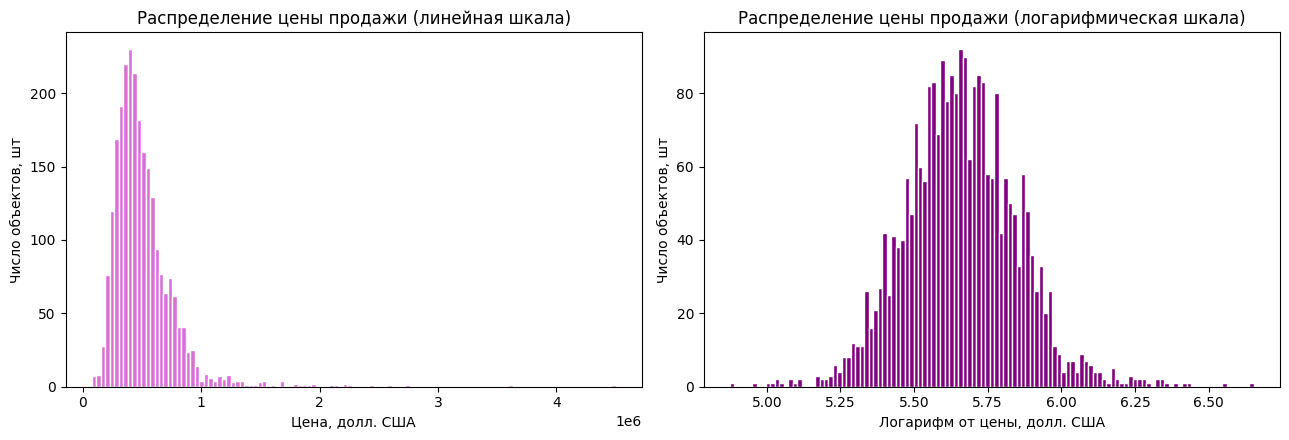

In [2]:
x = df[MAIN].dropna().to_numpy(float)
n = x.size
xmin, xmax = x.min(), x.max()

k_sturges = len(np.histogram_bin_edges(x, bins="sturges")) - 1
k_fd      = len(np.histogram_bin_edges(x, bins="fd")) - 1

ratio  = xmax / xmin
orders = np.log10(ratio)

def skew(v):
    m = v.mean(); d = v - m
    s2 = np.mean(d*d); s3 = np.mean(d*d*d)
    return 0.0 if s2 == 0 else s3 / s2**1.5

sk_before = skew(x)
sk_after  = skew(np.log(x))

print(f"n = {n}, min = {xmin:.0f}, max = {xmax:.0f}")
print(f"k по Стёрджесу = {k_sturges}, k по Фридман–Дьяконису = {k_fd}")
print(f"max/min = {ratio:.1f}, порядков = {orders:.2f}")
print(f"асимметрия до логарифма = {sk_before:.4f}, после = {sk_after:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(x, bins=k_fd, color="orchid", edgecolor="white")
axes[0].set_title("Распределение цены продажи (линейная шкала)")
axes[0].set_xlabel("Цена, долл. США"); axes[0].set_ylabel("Число объектов, шт")

axes[1].hist(np.log10(x), bins=k_fd, color="purple", edgecolor="white")
axes[1].set_title("Распределение цены продажи (логарифмическая шкала)")
axes[1].set_xlabel("Логарифм от цены, долл. США"); axes[1].set_ylabel("Число объектов, шт")

plt.tight_layout(); plt.show()

Взяли корзины по Фридману–Дьяконису, потому что правило Стёрджеса придумано для нормального (симметричного) распределения. У нас цена скошена — длинный хвост дорогих домов. На таких данных Стёрджес даёт слишком мало корзин и весь хвост сминается в один столбик. Правило Фридмана–Дьякониса смотрит на разброс «типичной» середины, поэтому выбросы его не раздувают, и оно даёт больше корзин => хвост видно.

Построили две версии - линейную и логарифмическую. Порядков у нас около 1.8 - формально чуть меньше двух, но асимметрия очень сильная. На линейной оси почти все дома слипаются у нуля, хвост не разглядеть. На лог-оси картина читается: распределение с одной вершиной, почти как у логнормального. Поэтому показываем обе, чтобы было видно, что линейная ось скрывает.

На графике видно: 1. Одна вершина - рынок в основном однородный; 2. Типичная цена - около медианы, а не среднего: среднее завышено дорогими домами; 3. Правый хвост длинный — это элитные объекты: у воды (waterfront=1), с лучшим видом (view=4), высоким классом (grade≥10), в престижных районах; 4. Лог-шкала показывает, что цена меняется в разы, а не на фиксированную сумму.

Что график не покажет: 1. Причинность (что именно «делает» цену такой); 2. Что происходит внутри хвоста - там меньше 1% точек, это шум для гистограммы; 3. Есть ли скрытые подгруппы в узких диапазонах


## ● Пункт 2. Разброс по группам

<sub>обязательный пункт · 1 балл</sub>

          n         mean    median          std    disp
y_clf                                                  
0      1610  514731.3124  455400.0  285030.5211  0.2082
1       875  490615.4697  440000.0  246110.5390  0.2057

Наибольшее расхождение: группа 0, disp = 0.2082, n = 1610


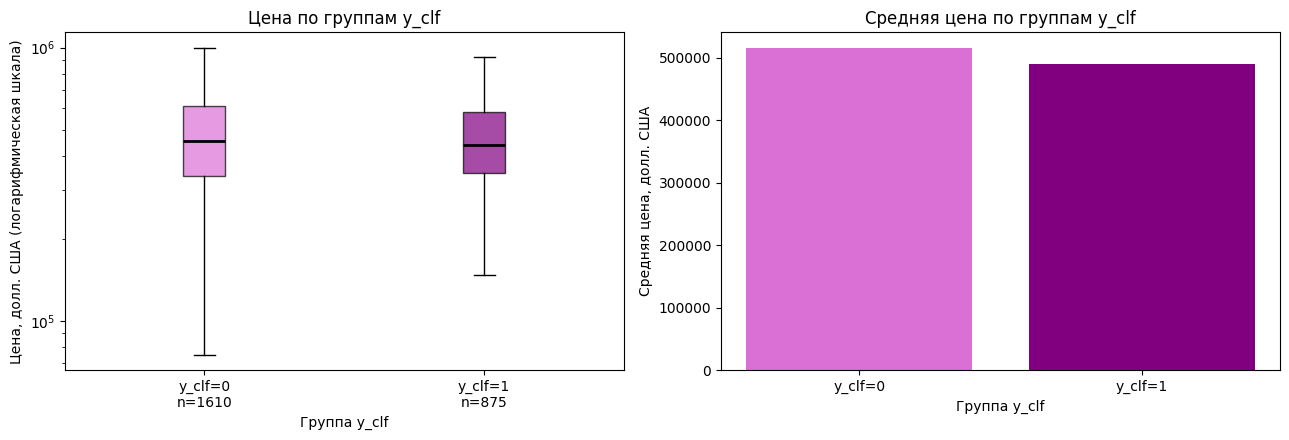

In [3]:
d = df[[GROUP, MAIN]].dropna()
x = d[MAIN].to_numpy(float)
grp = d[GROUP].to_numpy()

tmp = d.groupby(GROUP)[MAIN]
tab = tmp.agg(n="count", mean="mean", median="median")
tab["std"]  = tmp.std(ddof=0)
tab["disp"] = np.where(tab["std"] == 0, 0.0,
                       (tab["mean"] - tab["median"]).abs() / tab["std"].replace(0, np.nan))
print(tab.round(4))

worst = tab["disp"].idxmax()
print(f"\nНаибольшее расхождение: группа {worst}, disp = {tab.loc[worst,'disp']:.4f}, n = {int(tab.loc[worst,'n'])}")

levels = sorted(d[GROUP].unique())
boxes = [d.loc[d[GROUP] == lv, MAIN].to_numpy() for lv in levels]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bp = axes[0].boxplot(
    boxes,
    tick_labels=[f"{GROUP}={lv}\nn={len(b)}" for lv, b in zip(levels, boxes)],
    showfliers=False,
    patch_artist=True
)
colors = ["orchid","purple"]
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
    patch.set_edgecolor("black")
for med in bp["medians"]:
    med.set_color("black")
    med.set_linewidth(2)

axes[0].set_yscale("log")
axes[0].set_title("Цена по группам y_clf")
axes[0].set_xlabel("Группа y_clf")
axes[0].set_ylabel("Цена, долл. США (логарифмическая шкала)")

axes[1].bar([f"{GROUP}={lv}" for lv in levels], tab["mean"].values,
            color=["orchid","purple"], capsize=6)
axes[1].set_title("Средняя цена по группам y_clf")
axes[1].set_xlabel("Группа y_clf")
axes[1].set_ylabel("Средняя цена, долл. США")

plt.tight_layout()
plt.show()

По группам y_clf посчитаны размер, среднее, медиана и расхождение. Наибольшее расхождение зафиксировано у группы y_clf=0 (disp = 0.2082, n = 1610), в то время как у группы y_clf=1 оно немного меньше (disp = 0.2057, n = 875). Это означает, что в обеих группах распределение цен смещено вправо, и среднее значение завышено относительно медианы.

Для ящика с усами выбрана логарифмическая шкала. Цена в данных покрывает почти два порядка (от ~75 тыс. до ~4.5 млн), и внутри каждой группы присутствует длинный правый хвост из-за дорогих объектов. На линейной оси ящики сжались бы у нуля, а верхние усы ушли бы далеко вверх, что сделало бы форму распределения и разброс нечитаемыми. Логарифмическая шкала сжимает этот хвост и позволяет адекватно сравнить разброс и медианы групп.

Сравнивая два графика, можно увидеть главное ограничение диаграммы средних. Столбики показывают, что средняя цена в группе y_clf=0 визуально немного выше, чем в группе y_clf=1. Однако ящик с усами добавляет критически важный контекст: разброс цен внутри каждой группы огромен. Ящики и длинные усы сильно перекрываются, а разница между медианами значительно меньше, чем разброс цен внутри каждой группы.

Вывод, который напрашивался бы по диаграмме средних — «в группе 0 дома существенно дороже» — оказался бы неверным. Разница средних в 24 тыс. долларов на фоне разброса в сотни тысяч не позволяет говорить о каком-то значимом сдвиге. Более того, медианные цены различаются всего на 15 тыс., что подтверждает: типичный дом в обеих группах стоит примерно одинаково, а небольшая разница в средних обусловлена лишь вариацией дорогих объектов в хвостах распределения. Обе группы достаточно крупные (n = 1610 и n = 875), поэтому ящику с усами можно полностью доверять.

Эти графики не показывают причинность (влияет ли само состояние дома на цену или оба признака определяются третьим фактором), скрывают внутреннюю структуру групп (две вершины или смесь дорогих и дешевых сегментов внутри одного ящика не видны), игнорируют географию (сильное влияние на цену - локация, а мы не видим, равномерно ли группы распределены по дорогим и дешевым районам).

## ● Пункт 3. Связь двух величин

<sub>обязательный пункт · 1 балл</sub>

Пирсон   = 0.7325
Спирмен  = 0.7147
Разность = 0.0178



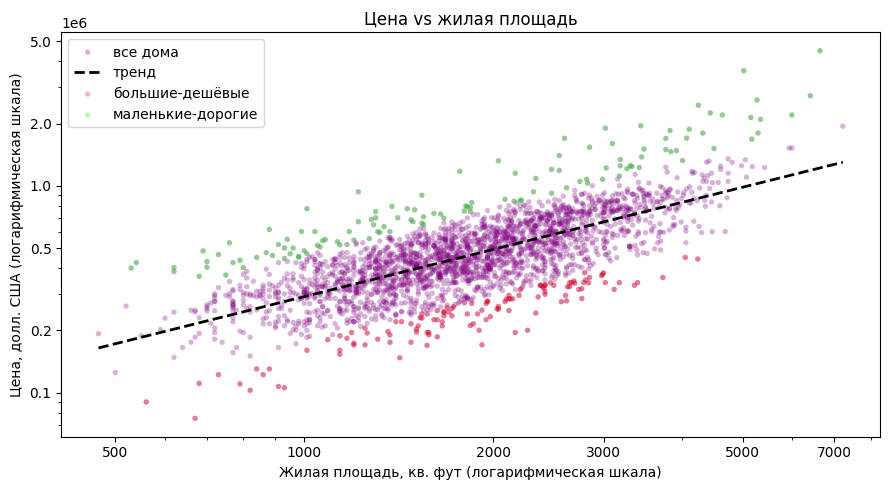


Большие, но дешёвые (красные): 
 sqft_living    price  waterfront  view  grade  bedrooms  bathrooms
        2770 317625.0           0     0      7         3       2.75
        1950 269950.0           0     2      7         3       1.50
        3730 360000.0           0     0      7         4       1.75
         880 130000.0           0     0      5         2       1.00
        1520 210000.0           0     0      6         4       2.00

Маленькие, но дорогие (зелёные):
 sqft_living     price  waterfront  view  grade  bedrooms  bathrooms
        1170  519950.0           0     0      8         3       2.25
        1010  470000.0           0     0      7         3       1.00
         770  425000.0           0     0      5         2       1.00
        1380  795000.0           0     2      5         2       1.00
        4250 2450000.0           0     3     10         4       4.25


In [4]:
d = df[["sqft_living","price"]].dropna()
a = d["sqft_living"].to_numpy(float)
b = d["price"].to_numpy(float)

def pearson(u,v):
    du=u-u.mean(); dv=v-v.mean()
    su=np.sqrt(np.mean(du*du)); sv=np.sqrt(np.mean(dv*dv))
    return 0.0 if su==0 or sv==0 else float(np.mean(du*dv)/(su*sv))

r_p = pearson(a,b)
ra = pd.Series(a).rank(method="average").to_numpy()
rb = pd.Series(b).rank(method="average").to_numpy()
r_s = pearson(ra,rb)
print(f"Пирсон   = {r_p:.4f}")
print(f"Спирмен  = {r_s:.4f}")
print(f"Разность = {abs(r_p - r_s):.4f}\n")

log_a = np.log10(a)
log_b = np.log10(b)
coef = np.polyfit(log_a, log_b, 1)
predicted_log_b = coef[0] * log_a + coef[1]
residuals = log_b - predicted_log_b

m_cheap = residuals <= np.quantile(residuals, 0.05)
m_rich  = residuals >= np.quantile(residuals, 0.95)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(a, b, s=15, alpha=0.3, color="purple", edgecolors="none", label="все дома")

xx = np.linspace(a.min(), a.max(), 100)
ax.plot(xx, 10**(coef[1]) * xx**coef[0], "k--", lw=2, label=f"тренд")

ax.scatter(a[m_cheap], b[m_cheap], s=15, color="red", alpha=0.3, edgecolors="none",
           label=f"большие-дешёвые")
ax.scatter(a[m_rich], b[m_rich], s=15, color="lime", alpha=0.3, edgecolors="none",
           label=f"маленькие-дорогие")

ax.set_xscale("log")
ax.set_yscale("log")
x_ticks = [500, 1000, 2000, 3000, 5000, 7000]
ax.set_xticks(x_ticks)
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.set_minor_formatter(NullFormatter())

y_ticks = [100_000, 200_000, 500_000, 1_000_000, 2_000_000, 5_000_000]
ax.set_yticks(y_ticks)
ax.yaxis.set_major_formatter(ScalarFormatter())
ax.yaxis.set_minor_formatter(NullFormatter())

ax.set_title("Цена vs жилая площадь")
ax.set_xlabel("Жилая площадь, кв. фут (логарифмическая шкала)")
ax.set_ylabel("Цена, долл. США (логарифмическая шкала)")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

cols = ["sqft_living", "price", "waterfront", "view", "grade", "bedrooms", "bathrooms"]

print("\nБольшие, но дешёвые (красные): ")
print(df.loc[m_cheap, cols].head(5).to_string(index=False))

print("\nМаленькие, но дорогие (зелёные):")
print(df.loc[m_rich, cols].head(5).to_string(index=False))

Коэффициенты Пирсона и Спирмена расходятся крайне слабо (разность всего 0.0178). Это означает, что связь между площадью и ценой почти строго линейная (в лог-масштабе) и в целом однородная.

Поскольку разность мала, сильных выбросов, переворачивающих картину, нет. Однако на графике хорошо видны два типа «возмутителей», задающих общий разброс. Красные точки (большие, но дешёвые) — это дома с большой площадью, но низкой ценой из-за плохого состояния (низкий grade, например 5-7) или отсутствия видовых характеристик (view=0). Они тянут прямую вниз. Зелёные точки (маленькие, но дорогие) — это объекты с небольшой площадью, но высокой ценой благодаря престижной локации, хорошему ремонту или виду (view=2, 3, grade до 10). Они тянут прямую вверх.

Связь не значит причину. Хотя площадь напрямую влияет на цену, здесь работает и скрытый фактор: качество (grade) и локация. Дома в престижных районах одновременно и больше, и дороже. Также возможна обратная логика: в дорогом сегменте рынка дома изначально строят большими, потому что покупатель платёжеспособен.

## ● Пункт 4. Категории и таблица сопряжённости

<sub>обязательный пункт · 1 балл</sub>

Счётчики:
 y_clf          0    1
waterfront           
0           1599  874
1             11    1

Доля от всей таблицы, %:
 y_clf           0      1
waterfront              
0           64.35  35.17
1            0.44   0.04

Доля от строки, %:
 y_clf           0      1
waterfront              
0           64.66  35.34
1           91.67   8.33

Доля от столбца, %:
 y_clf           0      1
waterfront              
0           99.32  99.89
1            0.68   0.11

Клетка (waterfront=1, y_clf=1):
  от таблицы  = 0.04%
  от строки   = 8.33%
  от столбца  = 0.11%


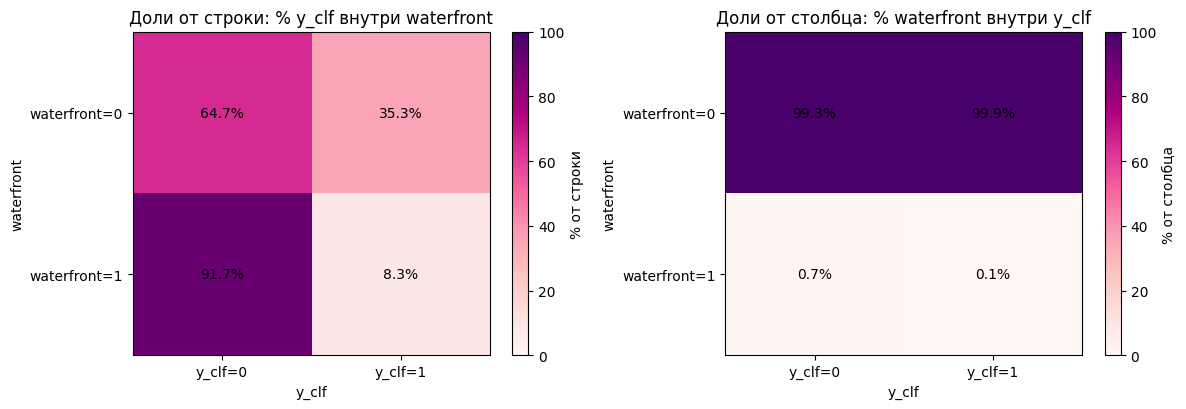

In [5]:
ct = pd.crosstab(df["waterfront"], df["y_clf"])
total = ct.values.sum()

share_row = ct.div(ct.sum(axis=1), axis=0) * 100
share_col = ct.div(ct.sum(axis=0), axis=1) * 100
share_tab = ct / total * 100

print("Счётчики:\n", ct)
print("\nДоля от всей таблицы, %:\n", share_tab.round(2))
print("\nДоля от строки, %:\n", share_row.round(2))
print("\nДоля от столбца, %:\n", share_col.round(2))

r, c = 1, 1
print(f"\nКлетка (waterfront=1, y_clf=1):")
print(f"  от таблицы  = {share_tab.loc[r,c]:.2f}%")
print(f"  от строки   = {share_row.loc[r,c]:.2f}%")
print(f"  от столбца  = {share_col.loc[r,c]:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

for ax, mat, title, cbl in [
    (axes[0], share_row.values, "Доли от строки: % y_clf внутри waterfront", "% от строки"),
    (axes[1], share_col.values, "Доли от столбца: % waterfront внутри y_clf", "% от столбца"),
]:
    im = ax.imshow(mat, cmap="RdPu", aspect="auto", vmin=0, vmax=100)
    ax.set_xticks([0,1], ["y_clf=0","y_clf=1"])
    ax.set_yticks([0,1], ["waterfront=0","waterfront=1"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{mat[i,j]:.1f}%", ha="center", va="center")
    ax.set_title(title); ax.set_xlabel("y_clf"); ax.set_ylabel("waterfront")
    plt.colorbar(im, ax=ax, label=cbl)

plt.tight_layout(); plt.show()

В качестве содержательного вопроса из области недвижимости можно взять: «Какая доля домов у воды (waterfront=1) находится в хорошем состоянии (y_clf=1)?». Ответ на него дает левая карта (доли от строки). Судя по ней, только 8.3% домов у воды находятся в хорошем состоянии, а подавляющее большинство (91.7%) - в плохом.

Если же мы зададим другой вопрос: «Какой вклад вносят дома у воды в общую массу домов в хорошем состоянии?», то на него отвечает правая карта (доли от столбца). Здесь доля домов у воды среди всех хороших домов составляет всего 0.1% (так как домов у воды в принципе очень мало).

Именно эти два числа наглядно показывают, почему нельзя путать нормализацию: 8.3% и 0.1% — это ответы на два принципиально разных вопроса.

Тепловые карты показывают совместное распределение признаков, но не доказывают причинно-следственную связь. Тот факт, что 91.7% домов у воды находятся в плохом состоянии, не означает, что наличие воды портит дом — это может объясняться тем, что большинство водных объектов в этом датасете — это старый фонд или дома в специфических районах.



## ○ Пункт 5. Проверка на парадокс Симпсона

<sub>дополнительный пункт · 1 балл</sub>

Общая корреляция (Пирсон): 0.7325
  y_clf=0: n=1610, r=0.7421
  y_clf=1: n=875, r=0.7074


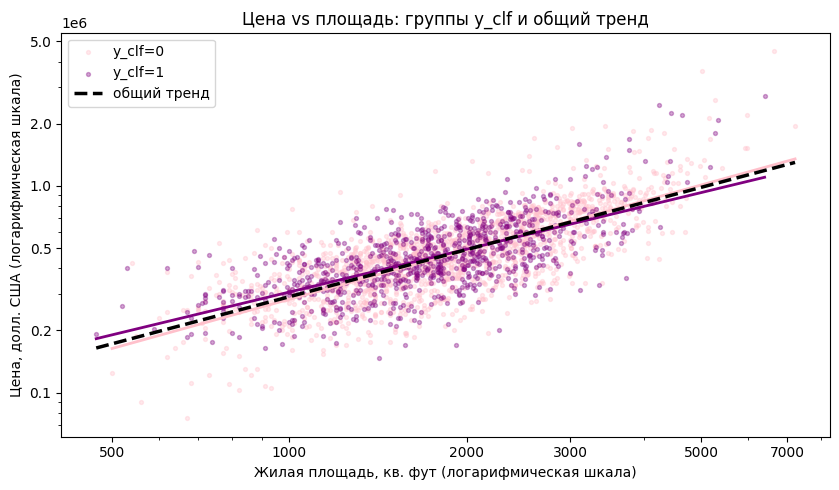

In [6]:
d = df[["sqft_living", "price", "y_clf"]].dropna()

def pearson(u, v):
    du = u - u.mean(); dv = v - v.mean()
    su = np.sqrt(np.mean(du*du)); sv = np.sqrt(np.mean(dv*dv))
    return 0.0 if su == 0 or sv == 0 else float(np.mean(du*dv) / (su*sv))

r_all = pearson(d["sqft_living"].values, d["price"].values)
print(f"Общая корреляция (Пирсон): {r_all:.4f}")
for lv, sub in d.groupby("y_clf"):
    r = pearson(sub["sqft_living"].values, sub["price"].values)
    print(f"  y_clf={lv}: n={len(sub)}, r={r:.4f}")

fig, ax = plt.subplots(figsize=(8.5, 5))

colors = {0: "pink", 1: "purple"}

for lv, sub in d.groupby("y_clf"):
    c = colors[lv]
    ax.scatter(sub["sqft_living"], sub["price"], s=8, alpha=0.35,
               color=c, label=f"y_clf={lv}")

    c_trend = np.polyfit(np.log10(sub["sqft_living"]), np.log10(sub["price"]), 1)
    xx = np.linspace(sub["sqft_living"].min(), sub["sqft_living"].max(), 100)
    ax.plot(xx, 10**(c_trend[1])*xx**c_trend[0], color=c, lw=2)

c_all = np.polyfit(np.log10(d["sqft_living"]), np.log10(d["price"]), 1)
xx = np.linspace(d["sqft_living"].min(), d["sqft_living"].max(), 100)
ax.plot(xx, 10**(c_all[1])*xx**c_all[0], "k--", lw=2.5, label="общий тренд")

ax.set_xscale("log")
ax.set_yscale("log")
x_ticks = [500, 1000, 2000, 3000, 5000, 7000]
ax.set_xticks(x_ticks)
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.set_minor_formatter(NullFormatter())

y_ticks = [100_000, 200_000, 500_000, 1_000_000, 2_000_000, 5_000_000]
ax.set_yticks(y_ticks)
ax.yaxis.set_major_formatter(ScalarFormatter())
ax.yaxis.set_minor_formatter(NullFormatter())

ax.set_title("Цена vs площадь: группы y_clf и общий тренд")
ax.set_xlabel("Жилая площадь, кв. фут (логарифмическая шкала)")
ax.set_ylabel("Цена, долл. США (логарифмическая шкала)")
ax.legend()
plt.tight_layout()
plt.show()

Парадокса Симпсона в данных нет. Общая корреляция равна 0.7325, и она полностью совпадает по направлению с корреляциями внутри групп: 0.7421 для y_clf=0 и 0.7074 для y_clf=1. Все три связи положительные, сильные и почти одинаковые.

На графике это видно по линиям тренда: розовая, фиолетовая и общая черная пунктирная линии идут почти параллельно. Группировка по признаку «хорошее состояние дома» (y_clf) не переворачивает связь площади и цены — в обеих группах больший метраж стабильно означает более высокую цену. Группы очень похожи по своей внутренней структуре, поэтому при их объединении общий тренд лишь плавно усредняет два почти идентичных тренда, а не искажает картину. Это числовой результат того, что скрытая переменная (y_clf) в данном случае не является смешивающим фактором для связи площади и цены.

## ○ Пункт 6. Пропуски как объект визуализации

<sub>дополнительный пункт · 1 балл</sub>

Пропуски по столбцам:
{'sqft_basement': 290}


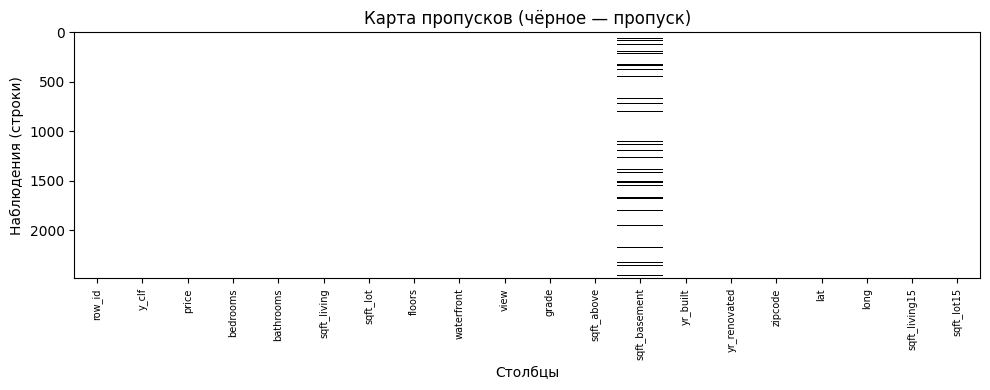

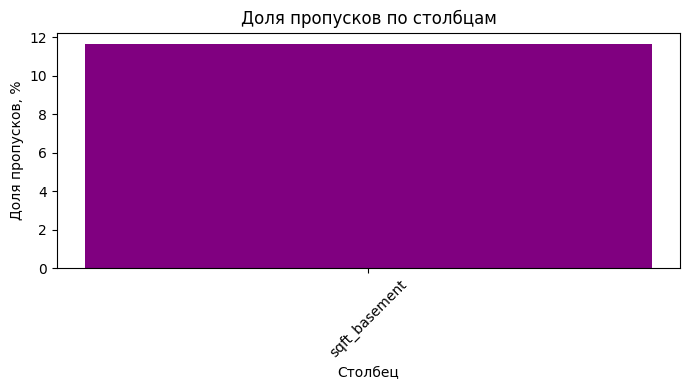


Пропусков в sqft_basement: 290 (11.7%)

sqft_above:
  median при пропуске = 1460.0
  median без пропуска = 1480.0

price:
  median при пропуске = 436900.0
  median без пропуска = 450000.0

grade:
  median при пропуске = 7.0
  median без пропуска = 7.0

waterfront:
  median при пропуске = 0.0
  median без пропуска = 0.0

Доля пропусков sqft_basement по waterfront:
{0: 11.73, 1: 0.0}


In [7]:
miss = df.isna()

print("Пропуски по столбцам:")
print(df.isna().sum()[df.isna().sum() > 0].to_dict())

fig, ax = plt.subplots(figsize=(10, 4))
ax.imshow(miss.values, aspect="auto", cmap="gray_r", interpolation="nearest")
ax.set_xticks(range(df.shape[1]))
ax.set_xticklabels(df.columns, rotation=90, fontsize=7)
ax.set_xlabel("Столбцы")
ax.set_ylabel("Наблюдения (строки)")
ax.set_title("Карта пропусков (чёрное — пропуск)")
plt.tight_layout(); plt.show()

frac = df.isna().mean().sort_values(ascending=False)
frac = frac[frac > 0]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(frac.index, frac.values * 100, color="purple")
ax.set_title("Доля пропусков по столбцам")
ax.set_xlabel("Столбец"); ax.set_ylabel("Доля пропусков, %")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

target = "sqft_basement"
has_na = df[target].isna()
print(f"\nПропусков в {target}: {has_na.sum()} ({has_na.mean()*100:.1f}%)")

for col in ["sqft_above", "price", "grade", "waterfront"]:
    print(f"\n{col}:")
    print(f"  median при пропуске = {df.loc[has_na, col].median():.1f}")
    print(f"  median без пропуска = {df.loc[~has_na, col].median():.1f}")

print("\nДоля пропусков sqft_basement по waterfront:")
print(df.groupby("waterfront")["sqft_basement"].apply(lambda s: s.isna().mean()*100).round(2).to_dict())

На карте пропусков видна одна вертикальная полоса: все пропуски (290 штук, или 11.7%) находятся только в столбце sqft_basement (площадь подвала). Горизонтальных пустых строк нет - пропуски разбросаны по всем домам.

Эти пропуски неслучайны. Это видно по связи с waterfront: если дом не у воды, пропуски есть в 11.7% случаев, а если дом у воды — пропусков нет вообще (0%). Также медианы цен и других признаков у домов с пропуском и без него почти одинаковые (например, цена 436 900 против 450 000). Это значит, что поле не заполняли просто потому, что у дома нет подвала — это не ошибка сбора данных и не «неизвестно», а естественное отсутствие значения.

Вывод. Столбец sqft_basement стоит оставить в анализе, но пропуски в нём нужно заполнить нулями. Остальные столбцы чистые.

## ○ Пункт 7. Много ли объясняет группировка

<sub>дополнительный пункт · 1 балл</sub>

Всего групп: 2
Общая сумма квадратов (SS_total): 1.8413e+14
Межгрупповая сумма квадратов (SS_between): 3.2970e+11
Внутригрупповая сумма квадратов (SS_within): 1.8380e+14
Доля объяснённой дисперсии (eta²): 0.0018 (0.18%)


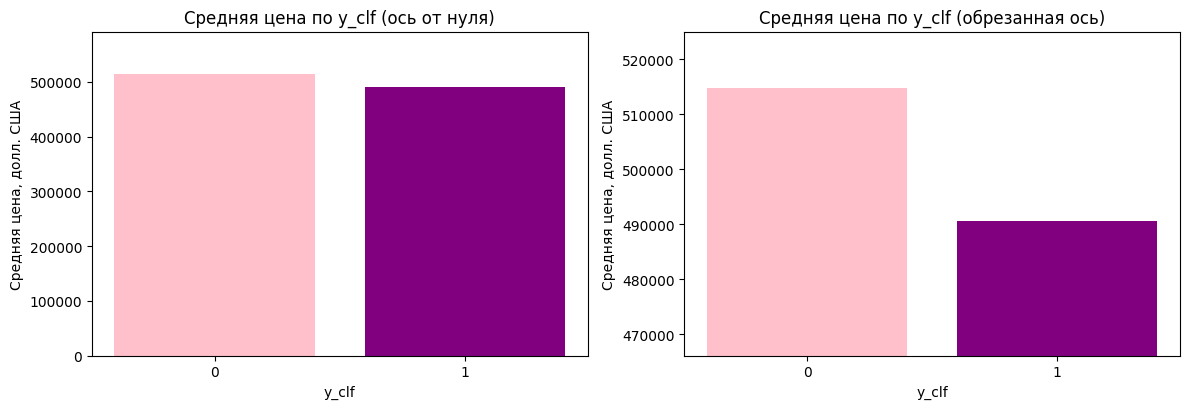

In [8]:
d = df[["price", "y_clf"]].dropna()
y = d["price"].to_numpy(float)
xbar = y.mean()

ss_total = np.sum((y - xbar)**2)

grp = d.groupby("y_clf")["price"]
cnt = grp.count().to_numpy()
mn = grp.mean().to_numpy()

ss_between = np.sum(cnt * (mn - xbar)**2)
ss_within = ss_total - ss_between
eta2 = ss_between / ss_total

print(f"Всего групп: {len(cnt)}")
print(f"Общая сумма квадратов (SS_total): {ss_total:.4e}")
print(f"Межгрупповая сумма квадратов (SS_between): {ss_between:.4e}")
print(f"Внутригрупповая сумма квадратов (SS_within): {ss_within:.4e}")
print(f"Доля объяснённой дисперсии (eta²): {eta2:.4f} ({eta2*100:.2f}%)")

levels = sorted(d["y_clf"].unique())
means = grp.mean().reindex(levels).values

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].bar([str(l) for l in levels], means, color=["pink", "purple"])
axes[0].set_ylim(0, means.max() * 1.15)
axes[0].set_title("Средняя цена по y_clf (ось от нуля)")
axes[0].set_xlabel("y_clf")
axes[0].set_ylabel("Средняя цена, долл. США")

axes[1].bar([str(l) for l in levels], means, color=["pink", "purple"])
axes[1].set_ylim(means.min() * 0.95, means.max() * 1.02)
axes[1].set_title("Средняя цена по y_clf (обрезанная ось)")
axes[1].set_xlabel("y_clf")
axes[1].set_ylabel("Средняя цена, долл. США")

plt.tight_layout()
plt.show()

Из чисел в выводе видно, что внутригрупповая сумма квадратов в сотни раз больше межгрупповой: цены внутри каждой группы разбросаны гораздо сильнее, чем различаются их средние.

Доля объяснённой дисперсии η2=0.0018 (всего 0.18%), что означает пренебрежимо малый эффект. Признак y_clf (хорошее состояние дома) практически не объясняет разброс цен. Оставшиеся 99.82% вариации цен обусловлены другими факторами - площадью, локацией, годом постройки и т.д.

Сравнение двух графиков отлично показывает, как обрезанная ось вводит в заблуждение. На графике с осью от нуля столбики почти одинаковые - визуально разница в 24 тыс. долларов на фоне 500 тыс. незаметна. Но на графике с обрезанной осью разница выглядит большой. Именно η2 расставляет всё по местам: эффект есть, но он ничтожно мал. Делать вывод, что «хорошее состояние дома определяет его цену», опираясь на обрезанный график, было бы грубой ошибкой.

## ○ Пункт 8. Три графика для заказчика

<sub>дополнительный пункт · 1 балл</sub>

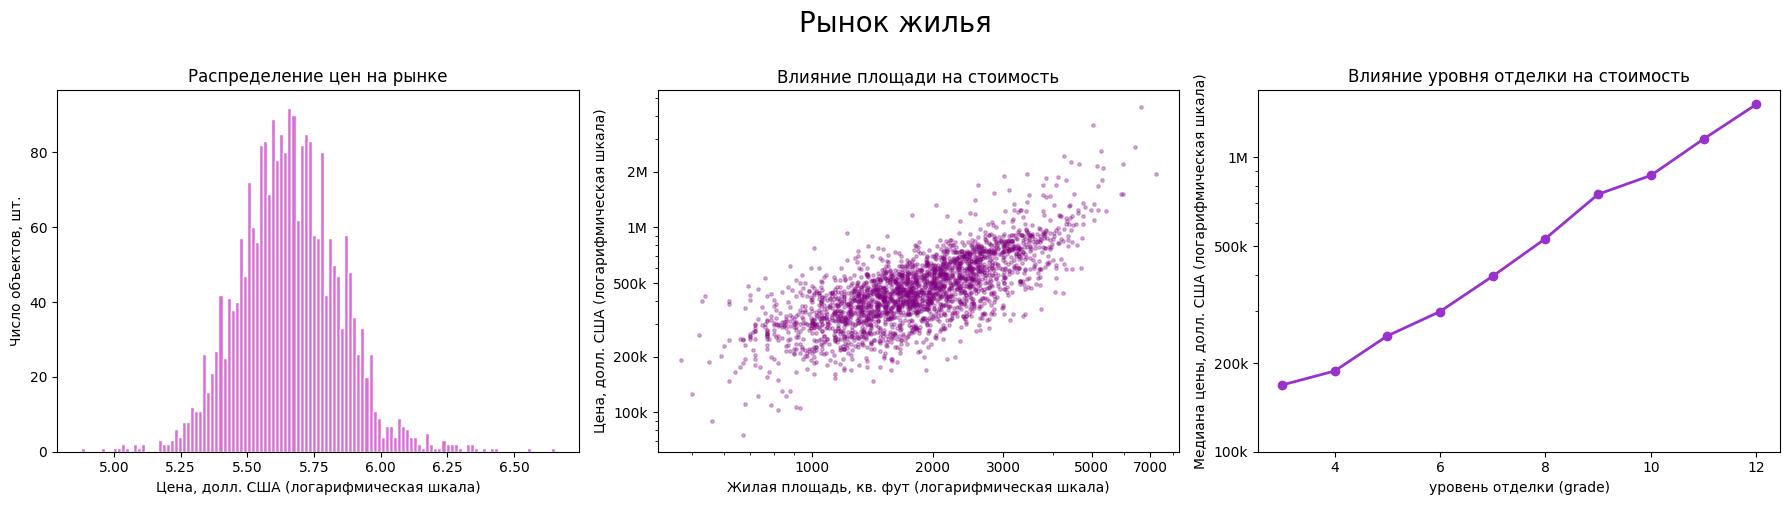

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

x = df["price"].dropna().to_numpy(float)
q1, q3 = np.quantile(x, [0.25, 0.75]); iqr = q3 - q1
k_fd = int(np.ceil((x.max()-x.min()) / (2*iqr/np.cbrt(len(x))))) if iqr > 0 else 30

axes[0].hist(np.log10(x), bins=k_fd, color="orchid", edgecolor="white")
axes[0].set_title("Распределение цен на рынке")
axes[0].set_xlabel("Цена, долл. США (логарифмическая шкала)")
axes[0].set_ylabel("Число объектов, шт.")

d = df[["sqft_living", "price"]].dropna()
a, b = d["sqft_living"].to_numpy(float), d["price"].to_numpy(float)
axes[1].scatter(a, b, s=6, alpha=0.3, color="purple")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("Влияние площади на стоимость")
axes[1].set_xlabel("Жилая площадь, кв. фут (логарифмическая шкала)")
axes[1].set_ylabel("Цена, долл. США (логарифмическая шкала)")

med = df.groupby("grade")["price"].median()
axes[2].plot(med.index, med.values, "o-", color="darkorchid", lw=2)
axes[2].set_yscale("log")
axes[2].set_title("Влияние уровня отделки на стоимость")
axes[2].set_xlabel("уровень отделки (grade)")
axes[2].set_ylabel("Медиана цены, долл. США (логарифмическая шкала)")

axes[1].set_xticks([1000, 2000, 3000, 5000, 7000])
axes[1].xaxis.set_major_formatter(ScalarFormatter())
axes[1].xaxis.set_minor_formatter(NullFormatter())
axes[1].set_yticks([100_000, 200_000, 500_000, 1_000_000, 2_000_000])
axes[1].set_yticklabels(["100k", "200k", "500k", "1M", "2M"])
axes[1].yaxis.set_minor_formatter(NullFormatter())

axes[2].set_xticks([4, 6, 8, 10, 12])
axes[2].set_yticks([100_000, 200_000, 500_000, 1_000_000])
axes[2].set_yticklabels(["100k", "200k", "500k", "1M"])
axes[2].yaxis.set_minor_formatter(NullFormatter())

fig.suptitle("Рынок жилья", fontsize=20, y=1.0)
plt.tight_layout()
plt.show()

Три выбранных графика складываются в логичную историю: сначала гистограмма показывает базовый разброс цен и длинный хвост, затем точечный график демонстрирует главный драйвер стоимости — площадь, а третий график добавляет скрытый фактор — уровень отделки, из-за которого дома одинаковой площади могут различаться в цене в разы.

Я отказалась от ящиков с усами (boxplot) из-за их статистической сложности — для заказчика, который видит данные впервые, квартили и выбросы будут непонятны без долгих объяснений.

Главный вопрос, который остался без ответа на этих графиках - «Где находится дом?». Площадь и отделка важны, но для недвижимости решающую роль играет география (престижный район, близость к центру или воде).

## ○ Пункт 9. График, который вы забраковали

<sub>дополнительный пункт · 1 балл</sub>

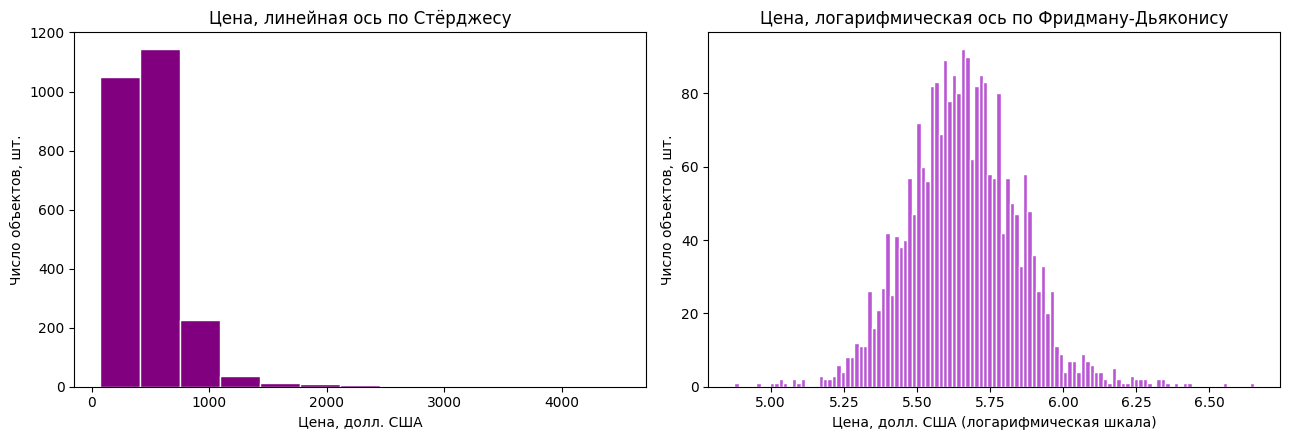

In [10]:
x = df["price"].dropna().to_numpy(float)

k_st = len(np.histogram_bin_edges(x, bins="sturges")) - 1
k_fd = len(np.histogram_bin_edges(x, bins="fd")) - 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(x / 1000, bins=k_st, color="purple", edgecolor="white")
axes[0].set_title(f"Цена, линейная ось по Стёрджесу")
axes[0].set_xlabel("Цена, долл. США")
axes[0].set_ylabel("Число объектов, шт.")

axes[1].hist(np.log10(x), bins=k_fd, color="mediumorchid", edgecolor="white")
axes[1].set_title(f"Цена, логарифмическая ось по Фридману-Дьяконису")
axes[1].set_xlabel("Цена, долл. США (логарифмическая шкала)")
axes[1].set_ylabel("Число объектов, шт.")

plt.tight_layout()
plt.show()

Первым я построила график на линейной оси с корзинами по Стёрджесу, но быстро отказалась от него. Линейная ось исказила картину: из-за длинного правого хвоста и огромных цен на дорогие дома 95% всех объектов слиплись в один столбик в самом начале (около 0–500 тыс.), а вся остальная часть рынка превратилась в неинформативную. Плюс правило Стёрджеса дало слишком мало корзин, что усугубило «слепоту» графика.

Замена на логарифмическую ось с корзинами по Фридману-Дьяконису полностью решила проблему. Благодаря логарифму широкий диапазон цен (от 75 тысяч до 4.5 млн) сжался в равномерный масштаб, и мы смогли увидеть реальную форму распределения.

Только после построения второго графика стало понялятно, что распределение цены одновершинное и близкое к логнормальному. Это означает, что цена меняется в разы, а не на фиксированную сумму.

---

## Перед сдачей

- [ ] Kernel → Restart & Run All прошёл без ошибок
- [ ] выводы ячеек сохранены в файле
- [ ] у каждого пункта есть письменный ответ
- [ ] на каждом графике подписаны обе оси
- [ ] в первой ячейке указаны фамилия, группа и номер варианта
- [ ] Контест по этому заданию принят — без него работа не рассматривается